In [8]:
import h5py

h5_file = "/pscratch/sd/x/xhall/dr3sim_v2/transients-0128-of-0256.h5"

with h5py.File(h5_file, "r") as f:
    print(list(f.keys()))

['FLUX_NATIVE', 'FLUX_OBS', 'FLUX_REST', 'IVAR_NATIVE', 'IVAR_OBS', 'IVAR_REST', 'META', 'RSFLUX_OBS', 'RSFLUX_REST', 'WAVE_NATIVE', 'WAVE_OBS', 'WAVE_REST']


In [ ]:
import h5py

h5_file = "/pscratch/sd/x/xhall/dr3sim_native/dataset.h5"

with h5py.File(h5_file, "r") as f:
    print(list(f.keys()))

wave: (150,)
flux: (4499843, 150)


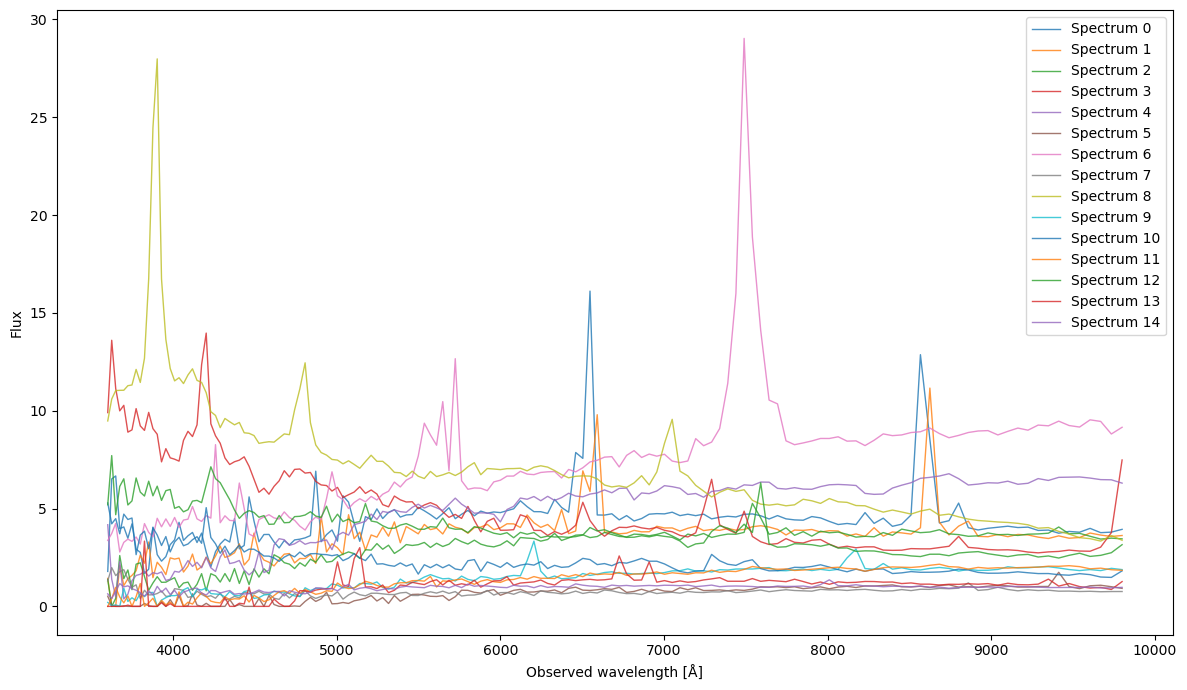

In [24]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

h5_file =  "/pscratch/sd/x/xhall/dr3sim_native/dataset.h5"

with h5py.File(h5_file, "r") as f:
    wave = f["WAVE_OBS"][:]
    flux = f["FLUX_OBS"][:]

print("wave:", wave.shape)
print("flux:", flux.shape)
n_plot = 15

plt.figure(figsize=(12, 7))

for i in range(n_plot):

    if wave.ndim == 1:
        w = wave
    else:
        w = wave[i]

    plt.plot(
        w,
        flux[i],
        lw=1,
        alpha=0.8,
        label=f"Spectrum {i}"
    )

plt.xlabel("Observed wavelength [Å]")
plt.ylabel("Flux")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
!open /pscratch/sd/x/xhall/dr3sim_v2/final_v2.png

/bin/bash: open: command not found


In [14]:
open final_v2.png

SyntaxError: invalid syntax (714611881.py, line 1)

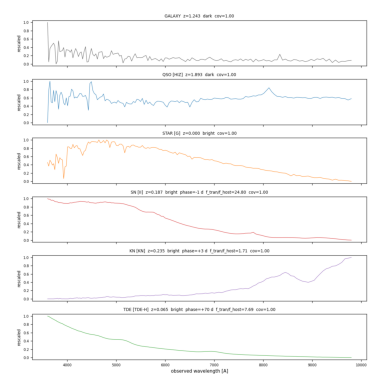

In [17]:
import matplotlib.pyplot as plt
from PIL import Image

# Open and display the image using data plotting
img = Image.open('/pscratch/sd/x/xhall/dr3sim_v2/final_v2.png')
plt.imshow(img)
plt.axis('off')  # Hides the graph pixel coordinates
plt.show()

In [8]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

h5_file = "/pscratch/sd/x/xhall/dr3sim_v3/dataset.h5"

trans_npz = "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transient_spectra_preprocess/batch_0000_prep_1000.npz"

n_plot = 10

with h5py.File(h5_file, "r") as f:
    h5_wave = f["WAVE_NATIVE"][:]
    h5_flux = f["FLUX_NATIVE"][:]

print("H5:")
print(" wave:", h5_wave.shape)
print(" flux:", h5_flux.shape)

with np.load(trans_npz, allow_pickle=True) as d:
    print("NPZ keys:", d.files)

    npz_wave = d["wave_grid"]
    npz_flux = d["X"]

print("NPZ:")
print(" wave:", npz_wave.shape)
print(" flux:", npz_flux.shape)

H5:
 wave: (7781,)
 flux: (4999842, 7781)
NPZ keys: ['TARGETID', 'SPECTYPE', 'wave_grid', 'X', 'W', 'M', 'norm', 'valid_frac', 'snr_orig', 'snr_proxy', 'keep_train']
NPZ:
 wave: (1000,)
 flux: (402, 1000)


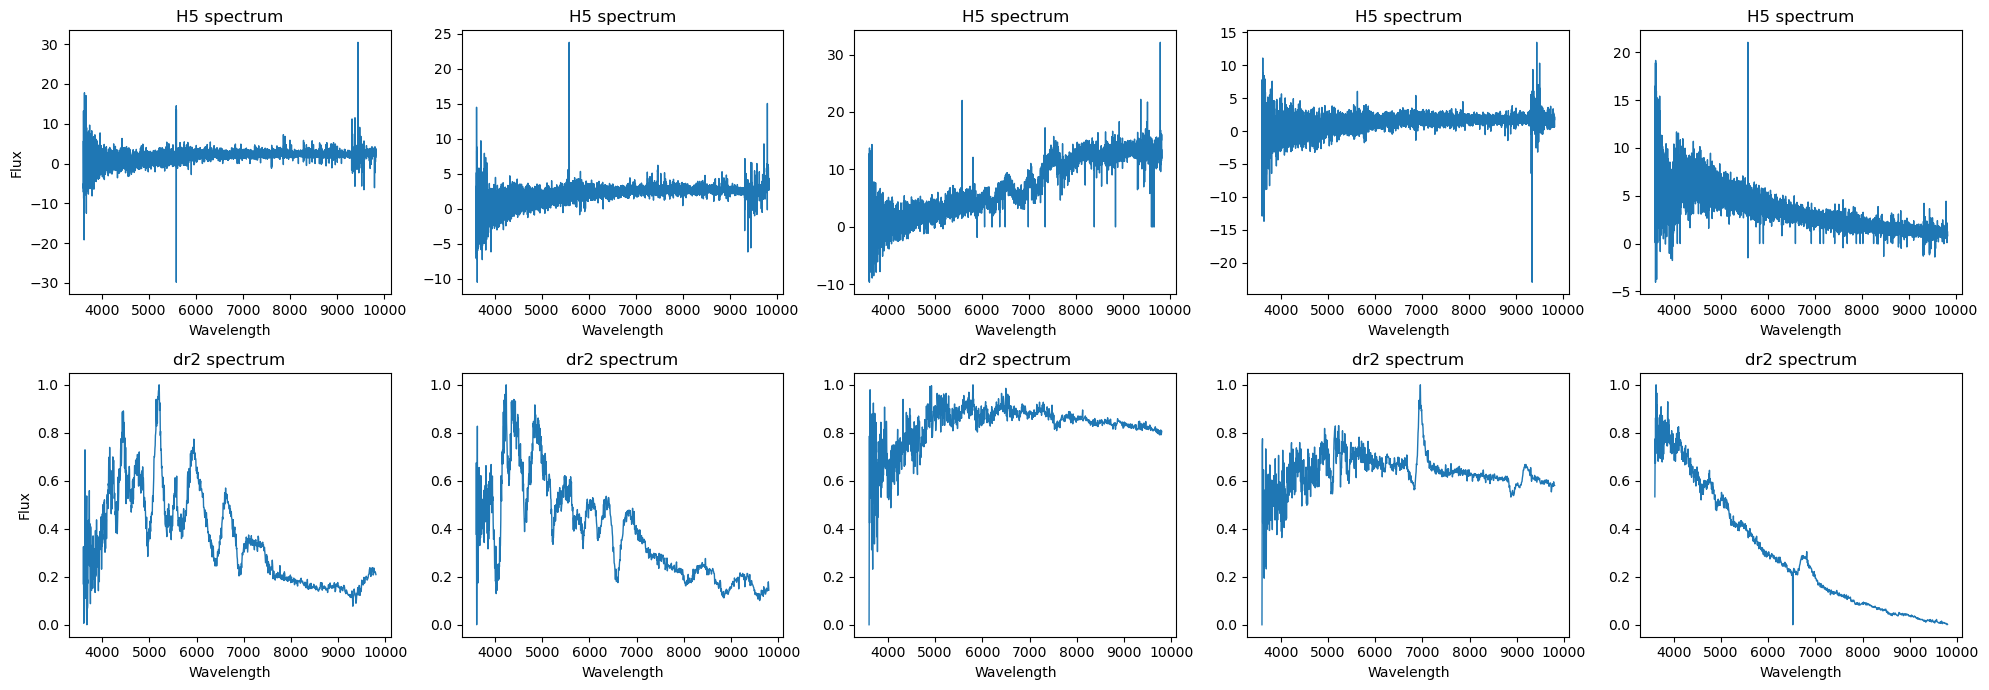

In [9]:
import matplotlib.pyplot as plt
import numpy as np

n_plot = 5

fig, axes = plt.subplots(
    2,
    n_plot,
    figsize=(4 * n_plot, 7),
    sharex=False
)

for i in range(n_plot):

    w_h5 = h5_wave if h5_wave.ndim == 1 else h5_wave[i+5]
    f_h5 = h5_flux[i+5]

    axes[0, i].plot(w_h5, f_h5, lw=1)
    axes[0, i].set_title(f"H5 spectrum")
    axes[0, i].set_xlabel("Wavelength")

    if i == 0:
        axes[0, i].set_ylabel("Flux")

    w_npz = npz_wave if npz_wave.ndim == 1 else npz_wave[i+5]
    f_npz = npz_flux[i+5]

    axes[1, i].plot(w_npz, f_npz, lw=1)
    axes[1, i].set_title(f"dr2 spectrum")
    axes[1, i].set_xlabel("Wavelength")

    if i == 0:
        axes[1, i].set_ylabel("Flux")

plt.tight_layout()
plt.show()

In [4]:
import numpy as np
from desitrip.preproc import rebin_flux, rescale_flux

import numpy as np
from desitrip.preproc import rebin_flux, rescale_flux


def preprocess_transients_arrays(
    flux_in,
    wave_in,
    ivar_in,
    targetid=None,
    spectype=None,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
    use_redshift=False,
    z_in=None,
):
    flux_in = np.asarray(flux_in, dtype=np.float32)
    wave_in = np.asarray(wave_in, dtype=np.float32)
    ivar_in = np.asarray(ivar_in, dtype=np.float32)

    if flux_in.ndim != 2:
        raise ValueError(f"flux_in must be 2D, got {flux_in.shape}")
    if ivar_in.shape != flux_in.shape:
        raise ValueError(f"ivar_in shape {ivar_in.shape} != flux_in shape {flux_in.shape}")

    N, L = flux_in.shape

    # Accept either common 1D wave grid or per-spectrum 2D wave grid
    if wave_in.ndim == 1:
        if wave_in.shape[0] != L:
            raise ValueError(f"wave_in shape {wave_in.shape} incompatible with flux_in shape {flux_in.shape}")
        wave_mode = "shared"
    elif wave_in.ndim == 2:
        if wave_in.shape != flux_in.shape:
            raise ValueError(f"wave_in shape {wave_in.shape} incompatible with flux_in shape {flux_in.shape}")
        wave_mode = "per_spectrum"
    else:
        raise ValueError(f"wave_in must be 1D or 2D, got shape {wave_in.shape}")

    if targetid is None:
        targetid = np.arange(N, dtype=np.int64)
    else:
        targetid = np.asarray(targetid)
        if len(targetid) != N:
            raise ValueError(f"targetid length {len(targetid)} != N={N}")

    if spectype is not None and len(spectype) != N:
        raise ValueError(f"spectype length {len(spectype)} != N={N}")

    if use_redshift:
        if z_in is None:
            raise ValueError("use_redshift=True but z_in is None")
        z_in = np.asarray(z_in, dtype=np.float32)
        if len(z_in) != N:
            raise ValueError(f"z_in length {len(z_in)} != N={N}")
    else:
        z_in = None

    # Original native-grid S/N
    valid_native = np.isfinite(flux_in) & np.isfinite(ivar_in) & (ivar_in > 0)
    if wave_mode == "shared":
        valid_native &= np.isfinite(wave_in)[None, :]
    else:
        valid_native &= np.isfinite(wave_in)

    snr_orig = np.zeros(N, dtype=np.float32)
    for i in range(N):
        if np.any(valid_native[i]):
            vals = np.abs(flux_in[i, valid_native[i]]) * np.sqrt(ivar_in[i, valid_native[i]])
            snr_orig[i] = np.float32(np.median(vals))

    # Full outputs
    wave_grid = (
        np.logspace(np.log10(minwave), np.log10(maxwave), nbins).astype(np.float32)
        if log else
        np.linspace(minwave, maxwave, nbins).astype(np.float32)
    )
    X = np.zeros((N, nbins), dtype=np.float32)
    W = np.zeros((N, nbins), dtype=np.float32)
    M = np.zeros((N, nbins), dtype=np.uint8)
    norm = np.ones(N, dtype=np.float32)

    # For per-spectrum wave grids, row-by-row rebinning is simplest and robust.
    # For shared wave grids, batch rebinning is fine.
    if wave_mode == "shared":
        flux_work = flux_in.copy()
        ivar_work = ivar_in.copy()

        bad = (~np.isfinite(flux_work)) | (~np.isfinite(ivar_work)) | (ivar_work <= 0)
        flux_work[bad] = 0.0
        ivar_work[bad] = 0.0

        keep_rows = np.count_nonzero(flux_work, axis=1) > 0
        nkeep = int(np.sum(keep_rows))

        if nkeep > 0:
            flux_keep = flux_work[keep_rows]
            ivar_keep = ivar_work[keep_rows]
            z_keep = z_in[keep_rows] if z_in is not None else None

            rewave, f_keep, w_keep = rebin_flux(
                wave=wave_in,
                flux=flux_keep,
                ivar=ivar_keep,
                z=z_keep,
                minwave=minwave,
                maxwave=maxwave,
                nbins=nbins,
                log=log,
                clip=False,
            )

            wave_grid = np.asarray(rewave, dtype=np.float32)
            out_rows = np.flatnonzero(keep_rows)

            for j, i in enumerate(out_rows):
                valid = np.isfinite(f_keep[j]) & np.isfinite(w_keep[j]) & (w_keep[j] > 0)
                if not np.any(valid):
                    continue

                fv = f_keep[j, valid]
                wv = w_keep[j, valid]

                fmin = np.min(fv)
                fmax = np.max(fv)
                scale = fmax - fmin

                if np.isfinite(scale) and scale > 0:
                    X[i, valid] = rescale_flux(fv).astype(np.float32)
                    W[i, valid] = (wv * (scale ** 2)).astype(np.float32)
                    norm[i] = np.float32(scale)
                else:
                    X[i, valid] = 0.0
                    W[i, valid] = 0.0
                    norm[i] = 1.0

                M[i, valid] = 1

    else:
        # Per-spectrum wavelength arrays
        for i in range(N):
            wi = wave_in[i].copy()
            fi = flux_in[i].copy()
            vi = ivar_in[i].copy()

            bad = (~np.isfinite(wi)) | (~np.isfinite(fi)) | (~np.isfinite(vi)) | (vi <= 0)
            wi = wi[~bad]
            fi = fi[~bad]
            vi = vi[~bad]

            if wi.size < 2:
                continue

            # Ensure increasing wavelength order
            order = np.argsort(wi)
            wi = wi[order]
            fi = fi[order]
            vi = vi[order]

            # Remove duplicate wavelengths if present
            uniq = np.diff(wi, prepend=wi[0] - 1) > 0
            wi = wi[uniq]
            fi = fi[uniq]
            vi = vi[uniq]

            if wi.size < 2:
                continue

            z_i = z_in[i] if z_in is not None else None

            rewave, f_out, w_out = rebin_flux(
                wave=wi,
                flux=fi,
                ivar=vi,
                z=z_i,
                minwave=minwave,
                maxwave=maxwave,
                nbins=nbins,
                log=log,
                clip=False,
            )

            wave_grid = np.asarray(rewave, dtype=np.float32)
            valid = np.isfinite(f_out) & np.isfinite(w_out) & (w_out > 0)

            if not np.any(valid):
                continue

            fv = f_out[valid]
            wv = w_out[valid]

            fmin = np.min(fv)
            fmax = np.max(fv)
            scale = fmax - fmin

            if np.isfinite(scale) and scale > 0:
                X[i, valid] = rescale_flux(fv).astype(np.float32)
                W[i, valid] = (wv * (scale ** 2)).astype(np.float32)
                norm[i] = np.float32(scale)
            else:
                X[i, valid] = 0.0
                W[i, valid] = 0.0
                norm[i] = 1.0

            M[i, valid] = 1

    valid_frac = M.mean(axis=1).astype(np.float32)

    snr_proxy = np.zeros(N, dtype=np.float32)
    for i in range(N):
        valid = M[i] > 0
        if np.any(valid):
            vals = np.abs(X[i, valid]) * np.sqrt(W[i, valid])
            snr_proxy[i] = np.float32(np.median(vals))

    keep_train = ((valid_frac >= 0.9) & (snr_orig >= 3.0)).astype(np.uint8)

    out = dict(
        TARGETID=targetid,
        wave_grid=wave_grid,
        X=X,
        W=W,
        M=M,
        norm=norm,
        valid_frac=valid_frac,
        snr_orig=snr_orig,
        snr_proxy=snr_proxy,
        keep_train=keep_train,
    )

    if spectype is not None:
        out["SPECTYPE"] = spectype

    return out

In [7]:
import os
import h5py
import numpy as np
from tqdm import tqdm

def preprocess_h5_in_batches(
    h5_file,
    out_dir,
    batch_size=1000,
    flux_key="FLUX_NATIVE",
    wave_key="WAVE_NATIVE",
    ivar_key="IVAR_NATIVE",
    meta_key="META",
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
):
    os.makedirs(out_dir, exist_ok=True)

    with h5py.File(h5_file, "r") as f:

        flux_ds = f[flux_key]
        ivar_ds = f[ivar_key]
        wave_ds = f[wave_key]

        N = flux_ds.shape[0]

        print("Number of spectra:", N)
        print("Flux shape:", flux_ds.shape)
        print("Wave shape:", wave_ds.shape)
        print("IVAR shape:", ivar_ds.shape)

        # Inspect metadata once
        meta_names = None
        if meta_key in f:
            meta_names = f[meta_key].dtype.names
            print("META fields:", meta_names)

        for start in tqdm(
            range(0, N, batch_size),
            desc="Preprocessing H5"
        ):
            end = min(start + batch_size, N)

            outfile = os.path.join(
                out_dir,
                f"batch_{start:08d}_{end:08d}.npz"
            )


            if os.path.exists(outfile):
                continue

            flux = np.asarray(
                flux_ds[start:end],
                dtype=np.float32
            )

            ivar = np.asarray(
                ivar_ds[start:end],
                dtype=np.float32
            )

            # wavelength can be shared or per-spectrum
            if wave_ds.ndim == 1:
                wave = np.asarray(
                    wave_ds[:],
                    dtype=np.float32
                )
            else:
                wave = np.asarray(
                    wave_ds[start:end],
                    dtype=np.float32
                )

            n_batch = end - start

            # fallback IDs
            targetid = np.arange(
                start,
                end,
                dtype=np.int64
            )

            spectype = None

            if meta_key in f and meta_names is not None:
                meta = f[meta_key][start:end]

                if "TARGETID" in meta_names:
                    targetid = np.asarray(
                        meta["TARGETID"]
                    ).astype(np.int64)

                if "TYPE" in meta_names:
                    spectype = np.asarray(meta["TYPE"])

                    if spectype.dtype.kind == "S":
                        spectype = np.char.decode(
                            spectype,
                            "utf-8"
                        )

                elif "SPECTYPE" in meta_names:
                    spectype = np.asarray(
                        meta["SPECTYPE"]
                    )

                    if spectype.dtype.kind == "S":
                        spectype = np.char.decode(
                            spectype,
                            "utf-8"
                        )

            prep = preprocess_transients_arrays(
                flux_in=flux,
                wave_in=wave,
                ivar_in=ivar,
                targetid=targetid,
                spectype=spectype,

                nbins=nbins,
                minwave=minwave,
                maxwave=maxwave,
                log=log,

                use_redshift=False,
            )

            outfile = os.path.join(
                out_dir,
                f"batch_{start:08d}_{end:08d}.npz"
            )

            np.savez_compressed(
                outfile,
                **prep
            )

            # Explicitly release large arrays
            del flux
            del ivar
            del wave
            del prep

    print("Done.")

In [8]:
h5_file = "/pscratch/sd/x/xhall/dr3sim_v3/dataset.h5"

out_dir = "/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed"

preprocess_h5_in_batches(
    h5_file=h5_file,
    out_dir=out_dir,
    batch_size=500,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
)

Number of spectra: 4999842
Flux shape: (4999842, 7781)
Wave shape: (7781,)
IVAR shape: (4999842, 7781)
META fields: ('LABEL', 'SUBTYPE', 'TARGETID', 'HOST_TARGETID', 'UNIQPIX', 'PROGRAM', 'SURVEY', 'Z', 'Z_CONF', 'EFFTIME_SPEC', 'IS_INJECTED', 'PHASE', 'RFLUXRATIO', 'DELTA_R', 'MODEL', 'COVFRAC_REST', 'COVFRAC_OBS', 'SPLIT')


Preprocessing H5: 100%|██████████| 10000/10000 [00:59<00:00, 167.69it/s]

Done.


In [9]:
import glob

files = sorted(
    glob.glob(
        "/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed/*.npz"
    )
)

print("Number of files:", len(files))
print(files[:5])

Number of files: 10000
['/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed/batch_00000000_00000500.npz', '/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed/batch_00000500_00001000.npz', '/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed/batch_00001000_00001500.npz', '/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed/batch_00001500_00002000.npz', '/global/cfs/cdirs/desi/users/zixinq/data/transim/preprocessed/batch_00002000_00002500.npz']


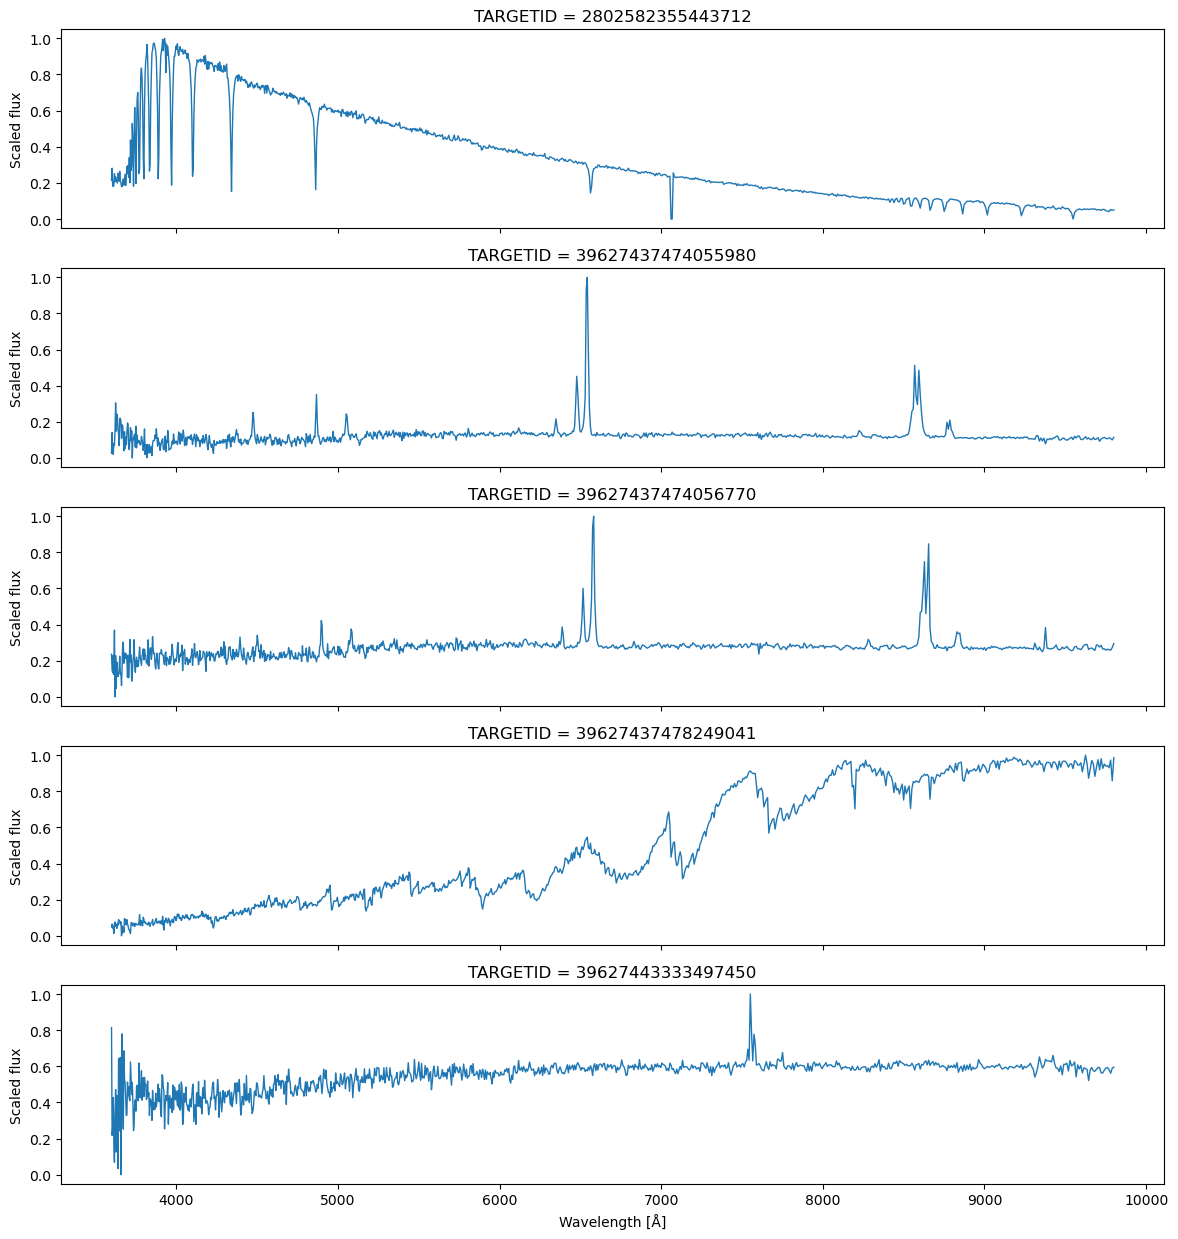

In [11]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

n_plot = 5

fig, axes = plt.subplots(
    n_plot, 1,
    figsize=(12, 2.5 * n_plot),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(
        wave,
        X[i],
        lw=1
    )

    ax.set_ylabel("Scaled flux")
    ax.set_title(f"TARGETID = {targetid[i]}")

axes[-1].set_xlabel("Wavelength [Å]")

plt.tight_layout()
plt.show()